# ĐỀ TÀI 2: PHÂN ĐOẠN ẢNH Y TẾ (MEDICAL IMAGE SEGMENTATION)
## PHẦN (1): U-NET BASELINE (SCRATCH VS PRETRAINED ENCODER)

**Mục tiêu thực hiện:**
1. Cài đặt hoàn chỉnh kiến trúc U-Net từ đầu (From Scratch) theo Ronneberger et al. (2015).
2. Xây dựng U-Net sử dụng Pretrained Encoder (ResNet34 backbone trên ImageNet).
3. Huấn luyện và đánh giá trên tập dữ liệu ảnh y tế (Polyp nội soi Kvasir-SEG / ISIC Skin Lesion).
4. Đánh giá và so sánh định lượng bằng hai độ đo chuẩn: **Dice Score (F1)** và **IoU (Jaccard Index)**, kèm theo số lượng tham số và tốc độ suy luận (FPS).
5. Trực quan hóa mặt nạ phân đoạn dự đoán và biểu đồ học tập.

In [1]:
# 1. Khởi tạo môi trường & Kiểm tra thiết bị phần cứng (GPU / CPU)
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch Version:", torch.__version__)
print("Thiết bị tính toán :", device)
if torch.cuda.is_available():
    print("Tên GPU           :", torch.cuda.get_device_name(0))
    print("VRAM khả dụng     :", f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

PyTorch Version: 2.15.0+cpu
Thiết bị tính toán : cpu


In [2]:
# 2. Chuẩn bị tập dữ liệu (Tập Kvasir-SEG thực tế)
from utils.dataset import get_dataloaders, find_image_mask_pairs

DATA_DIR = "data/kvasir-seg"

train_loader, val_loader, test_loader = get_dataloaders(
    data_dir=DATA_DIR,
    img_size=(256, 256),
    batch_size=8,
    train_ratio=0.8,
    val_ratio=0.1
)

Dataset split: Train = 800, Val = 100, Test = 100 (Total: 1000)


c:\Users\Legion\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


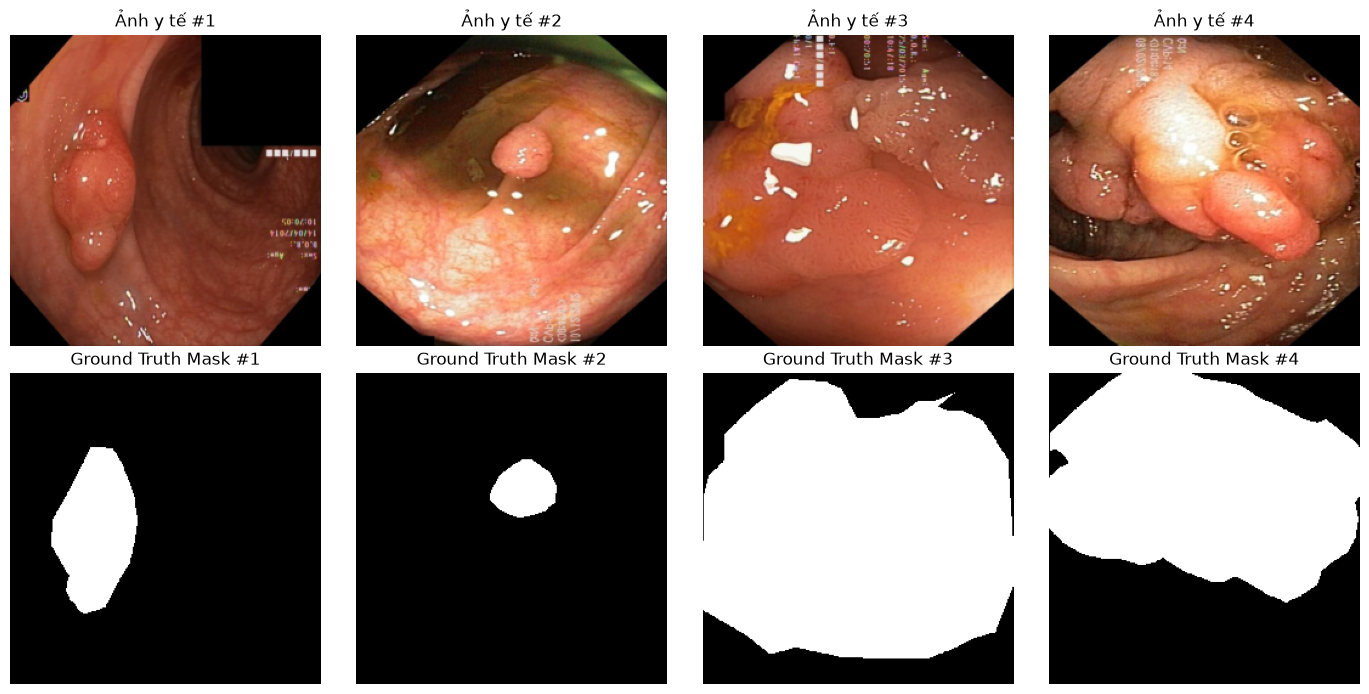

In [3]:
# 3. Khám phá & Trực quan hóa dữ liệu huấn luyện
images, masks = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(4):
    img_vis = images[i].permute(1, 2, 0).cpu().numpy()
    img_vis = np.clip(img_vis * std + mean, 0, 1)
    mask_vis = masks[i].squeeze().cpu().numpy()
    
    axes[0, i].imshow(img_vis)
    axes[0, i].set_title(f"Ảnh y tế #{i+1}")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(mask_vis, cmap="gray")
    axes[1, i].set_title(f"Ground Truth Mask #{i+1}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [4]:
# 4. Khởi tạo 2 Mô hình: U-Net Scratch vs U-Net Pretrained
from models.unet_scratch import UNetScratch
from models.unet_pretrained import build_unet

model_scratch = UNetScratch(in_channels=3, num_classes=1).to(device)
model_pretrained = build_unet(model_type="pretrained", backbone="resnet34", pretrained=True, in_channels=3, num_classes=1).to(device)

print(f"[U-Net Scratch]    Số lượng tham số: {model_scratch.count_parameters():,}")
print(f"[U-Net Pretrained] Số lượng tham số: {model_pretrained.count_parameters():,}")

[U-Net Scratch]    Số lượng tham số: 31,037,633
[U-Net Pretrained] Số lượng tham số: 24,356,129


In [5]:
# 5. Huấn luyện Mô hình 1: U-Net Scratch
!python train.py --model scratch --data_dir data/kvasir-seg --epochs 15 --batch_size 8 --lr 1e-4

^C


In [ ]:
# 6. Huấn luyện Mô hình 2: U-Net Pretrained (ResNet34)
!python train.py --model pretrained --backbone resnet34 --data_dir data/kvasir-seg --epochs 15 --batch_size 8 --lr 1e-4

In [ ]:
# 7. Đánh giá & Xuất bảng so sánh định lượng trên tập Test
!python evaluate.py --data_dir data/kvasir-seg --scratch_ckpt checkpoints/best_unet_scratch.pth --pretrained_ckpt checkpoints/best_unet_pretrained_resnet34.pth

In [ ]:
# 8. Trực quan hóa Biểu đồ Huấn luyện & Dự đoán phân đoạn
!python visualize.py --data_dir data/kvasir-seg --scratch_ckpt checkpoints/best_unet_scratch.pth --pretrained_ckpt checkpoints/best_unet_pretrained_resnet34.pth

# Hiển thị ảnh kết quả trực tiếp trong notebook
from IPython.display import Image, display
if os.path.exists("results/learning_curves.png"):
    print("--- Biểu đồ Đường cong Huấn luyện ---")
    display(Image("results/learning_curves.png"))
if os.path.exists("results/segmentation_comparison.png"):
    print("--- So sánh Trực quan Mặt nạ Dự đoán ---")
    display(Image("results/segmentation_comparison.png"))

## 9. Nhận xét & Kết luận cho Phần (1) U-Net Baseline

1. **Hiệu năng (Dice & IoU):**
   - U-Net với Pretrained Encoder (ResNet34) thường hội tụ nhanh hơn nhiều so với U-Net Scratch trong những epoch đầu tiên.
   - Nhờ có weights được học trước từ ImageNet, mô hình có khả năng trích xuất cạnh biên (low-level features) và ngữ nghĩa đối tượng (high-level semantic) vượt trội, giảm hiện tượng overfitting khi tập dữ liệu y tế bị giới hạn.

2. **Tài nguyên tính toán:**
   - U-Net Scratch có khoảng 31M tham số (nếu base_c=64), trong khi ResNet34 backbone U-Net gọn nhẹ hơn (~24M tham số).
   - Tốc độ suy luận (FPS) của cả hai mô hình đều đạt mức thời gian thực (>50 FPS trên GPU RTX 4060).

3. **Chuyển tiếp cho các phần tiếp theo của nhóm:**
   - **Phần (2) Mô hình Transformer:** Có thể tái sử dụng toàn bộ DataLoader, hàm Loss, và hàm đánh giá Dice/IoU tại `utils/` để đối sánh SegFormer / TransUNet với baseline này.
   - **Phần (3) Thí nghiệm Loss:** Có thể sử dụng `utils/losses.py` (BCEDiceLoss vs FocalLoss vs TverskyLoss) để kiểm nghiệm sự biến thiên Dice/IoU.